In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import dagshub
import mlflow

# DagsHub repository configuration
REPO_OWNER = "krishnagupta96321"
REPO_NAME = "Sentinel-risk-engine"

# Initialize MLflow tracking
dagshub.init( repo_owner=REPO_OWNER, repo_name=REPO_NAME, mlflow=True)

# Set experiment
mlflow.set_experiment("01_Model_Architecture_Benchmarking")

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Active experiment:", mlflow.get_experiment_by_name(
    "01_Model_Architecture_Benchmarking"
).name)

Accessing as krishnagupta96321

Initialized MLflow to track repo "krishnagupta96321/Sentinel-risk-engine"

Repository krishnagupta96321/Sentinel-risk-engine initialized!

MLflow tracking URI: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow
Active experiment: 01_Model_Architecture_Benchmarking


In [3]:
import numpy as np

In [4]:
import pandas as pd

# Load engineered dataset from Notebook 03
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "fraud_features.parquet"
df = pd.read_parquet(DATA_PATH)

# Remove unnecessary columns if present
drop_cols = [c for c in ["Unnamed: 0", ""] if c in df.columns]
if drop_cols:
    df.drop(columns=drop_cols, inplace=True)

# Ensure chronological ordering
if not df["unix_time"].is_monotonic_increasing:
    df.sort_values(by="unix_time", inplace=True)
    df.reset_index(drop=True, inplace=True)

# Chronological split: 70% Train, 15% Validation, 15% Test
total_rows = len(df)
train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print(f"Dataset shape: {df.shape}")
print(f"Train: {len(train_df):,} rows")
print(f"Validation: {len(val_df):,} rows")
print(f"Test: {len(test_df):,} rows")

Dataset shape: (1296675, 34)
Train: 907,672 rows
Validation: 194,501 rows
Test: 194,502 rows


In [5]:
# Verify engineered features from Notebook 03

static_features = [
    "haversine_dist_km",
    "log_amt",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "is_weekend"
]

velocity_features = [
    "tx_count_1h",
    "tx_sum_1h",
    "tx_count_24h",
    "tx_sum_24h"
]

engineered_features = static_features + velocity_features

# Check feature availability
missing_features = [
    col for col in engineered_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(f"Missing engineered features: {missing_features}")

print(f"Static engineered features: {len(static_features)}")
print(f"Velocity features: {len(velocity_features)}")
print(f"Total engineered features: {len(engineered_features)}")
print("All engineered features are available.")

Static engineered features: 7
Velocity features: 4
Total engineered features: 11
All engineered features are available.


In [6]:
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

# Static features (9)
static_features = [
    "amt", "log_amt", "city_pop", "haversine_dist_km",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend"
]

# Static + velocity features (13)
velocity_features = static_features + [
    "tx_count_1h", "tx_sum_1h",
    "tx_count_24h", "tx_sum_24h"
]

target_col = "is_fraud"

# Evaluation metrics
def evaluate_predictions(y_true, y_probs):
    return {
        "pr_auc": average_precision_score(y_true, y_probs),
        "roc_auc": roc_auc_score(y_true, y_probs),
        "brier_score": brier_score_loss(y_true, y_probs)
    }

print(f"Static features: {len(static_features)}")
print(f"Velocity features: {len(velocity_features)}")
print(f"Target column: {target_col}")

Static features: 9
Velocity features: 13
Target column: is_fraud


## Model Benchmarking

# 1. Logistic Regression — Static Features (9)

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Select static features
X_train_lr = train_df[static_features]
X_val_lr = val_df[static_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

with mlflow.start_run(run_name="logistic_regression_static") as run:

    # Log model metadata and parameters
    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("feature_set", "static")
    mlflow.log_param("features", static_features)
    mlflow.log_param("num_features", len(static_features))
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("C", 1.0)

    # Build pipeline
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            C=1.0,
            random_state=42
        ))
    ])

    # Train
    pipe.fit(X_train_lr, y_train)

    # Validation predictions
    val_probs_lr = pipe.predict_proba(X_val_lr)[:, 1]

    # Evaluate
    val_metrics_lr = evaluate_predictions(y_val, val_probs_lr)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_lr["pr_auc"],
        "val_roc_auc": val_metrics_lr["roc_auc"],
        "val_brier_score": val_metrics_lr["brier_score"]
    })

    # Log model
    mlflow.sklearn.log_model(pipe, artifact_path="model")

    # Save run ID for later diagnostics
    lr_run_id = run.info.run_id

    print("Logistic Regression — Static Features")
    print(f"Validation PR-AUC: {val_metrics_lr['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_lr['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_lr['brier_score']:.4f}")
    print(f"MLflow Run ID: {lr_run_id}")

2026/11/04 15:39:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logistic Regression — Static Features
Validation PR-AUC: 0.2584
Validation ROC-AUC: 0.9358
Validation Brier Score: 0.0840
MLflow Run ID: 822e7e77409a480fb6b1eae5d1bcc22b
🏃 View run logistic_regression_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/822e7e77409a480fb6b1eae5d1bcc22b
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


# 2. LightGBM — Static Features (9)

In [8]:
import lightgbm as lgb

# Select static features
X_train_lgb = train_df[static_features]
X_val_lgb = val_df[static_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

# LightGBM parameters
lgb_params = {
    "objective": "binary",
    "metric": "average_precision",
    "boosting_type": "gbdt",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "scale_pos_weight": 1.0,
    "random_state": 42,
    "n_jobs": -1
}

with mlflow.start_run(run_name="lightgbm_static") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "LightGBM")
    mlflow.log_param("feature_set", "static")
    mlflow.log_param("features", static_features)
    mlflow.log_param("num_features", len(static_features))
    mlflow.log_params(lgb_params)

    # Initialize model
    model_lgb = lgb.LGBMClassifier(**lgb_params)

    # Train with validation-based early stopping
    model_lgb.fit(
        X_train_lgb,
        y_train,
        eval_set=[(X_val_lgb, y_val)],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=30,
                verbose=False
            )
        ]
    )

    # Validation predictions
    val_probs_lgb = model_lgb.predict_proba(X_val_lgb)[:, 1]

    # Evaluate
    val_metrics_lgb = evaluate_predictions(y_val, val_probs_lgb)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_lgb["pr_auc"],
        "val_roc_auc": val_metrics_lgb["roc_auc"],
        "val_brier_score": val_metrics_lgb["brier_score"]
    })

    # Log model artifact
    mlflow.lightgbm.log_model(model_lgb, name="model")

    # Store run ID
    lgb_static_run_id = run.info.run_id

    print("LightGBM — Static Features")
    print(f"Validation PR-AUC: {val_metrics_lgb['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_lgb['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_lgb['brier_score']:.4f}")
    print(f"Best iteration: {model_lgb.best_iteration_}")
    print(f"MLflow Run ID: {lgb_static_run_id}")

c:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 5121, number of negative: 902551
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014404 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1068
[LightGBM] [Info] Number of data points in the train set: 907672, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.005642 -> initscore=-5.171875
[LightGBM] [Info] Start training from score -5.171875
LightGBM — Static Features
Validation PR-AUC: 0.5764
Validation ROC-AUC: 0.9812
Validation Brier Score: 0.0038
Best iteration: 27
MLflow Run ID: 1efbc40b93174295a65f81832223cc24
🏃 View run lightgbm_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/1efbc40b93174295a65f81832223cc24
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


# 3. 3 LightGBM — Static + Velocity Features (13)

In [9]:
# Select static + velocity features
X_train_lgb_v = train_df[velocity_features]
X_val_lgb_v = val_df[velocity_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

with mlflow.start_run(run_name="lightgbm_static_velocity") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "LightGBM")
    mlflow.log_param("feature_set", "static_velocity")
    mlflow.log_param("features", velocity_features)
    mlflow.log_param("num_features", len(velocity_features))
    mlflow.log_params(lgb_params)

    # Initialize model
    model_lgb_v = lgb.LGBMClassifier(**lgb_params)

    # Train with validation-based early stopping
    model_lgb_v.fit(
        X_train_lgb_v,
        y_train,
        eval_set=[(X_val_lgb_v, y_val)],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=30,
                verbose=False
            )
        ]
    )

    # Validation predictions
    val_probs_lgb_v = model_lgb_v.predict_proba(X_val_lgb_v)[:, 1]

    # Evaluate
    val_metrics_lgb_v = evaluate_predictions(y_val, val_probs_lgb_v)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_lgb_v["pr_auc"],
        "val_roc_auc": val_metrics_lgb_v["roc_auc"],
        "val_brier_score": val_metrics_lgb_v["brier_score"]
    })

    # Log model artifact
    mlflow.lightgbm.log_model(model_lgb_v, name="model")

    # Store run ID
    lgb_velocity_run_id = run.info.run_id

    print("LightGBM — Static + Velocity Features")
    print(f"Number of features: {len(velocity_features)}")
    print(f"Validation PR-AUC: {val_metrics_lgb_v['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_lgb_v['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_lgb_v['brier_score']:.4f}")
    print(f"Best iteration: {model_lgb_v.best_iteration_}")
    print(f"MLflow Run ID: {lgb_velocity_run_id}")

c:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 5121, number of negative: 902551
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.060052 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1617
[LightGBM] [Info] Number of data points in the train set: 907672, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.005642 -> initscore=-5.171875
[LightGBM] [Info] Start training from score -5.171875
LightGBM — Static + Velocity Features
Number of features: 13
Validation PR-AUC: 0.8606
Validation ROC-AUC: 0.9953
Validation Brier Score: 0.0019
Best iteration: 91
MLflow Run ID: f677baeb6205407ebad973d17a238481
🏃 View run lightgbm_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/f677baeb6205407ebad973d17a238481
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-

# 4 Random Forest — Static Features (9)

In [10]:
from sklearn.ensemble import RandomForestClassifier

# Select static features
X_train_rf = train_df[static_features]
X_val_rf = val_df[static_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

# Random Forest parameters
rf_params = {
    "n_estimators": 300,
    "max_depth": 20,
    "min_samples_split": 10,
    "min_samples_leaf": 5,
    "class_weight": "balanced_subsample",
    "random_state": 42,
    "n_jobs": -1
}

with mlflow.start_run(run_name="random_forest_static") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "RandomForest")
    mlflow.log_param("feature_set", "static")
    mlflow.log_param("features", static_features)
    mlflow.log_param("num_features", len(static_features))
    mlflow.log_params(rf_params)

    # Initialize model
    model_rf = RandomForestClassifier(**rf_params)

    # Train
    model_rf.fit(X_train_rf, y_train)

    # Validation predictions
    val_probs_rf = model_rf.predict_proba(X_val_rf)[:, 1]

    # Evaluate
    val_metrics_rf = evaluate_predictions(y_val, val_probs_rf)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_rf["pr_auc"],
        "val_roc_auc": val_metrics_rf["roc_auc"],
        "val_brier_score": val_metrics_rf["brier_score"]
    })

    # Log model artifact
    mlflow.sklearn.log_model(model_rf, artifact_path="model",skops_trusted_types=["sklearn.tree._tree.Tree"])

    # Store run ID
    rf_static_run_id = run.info.run_id

    print("Random Forest — Static Features")
    print(f"Number of features: {len(static_features)}")
    print(f"Validation PR-AUC: {val_metrics_rf['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_rf['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_rf['brier_score']:.4f}")
    print(f"MLflow Run ID: {rf_static_run_id}")

2026/11/04 15:43:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Random Forest — Static Features
Number of features: 9
Validation PR-AUC: 0.6157
Validation ROC-AUC: 0.9775
Validation Brier Score: 0.0069
MLflow Run ID: ad57bdc68550488b97516488d77b0ff1
🏃 View run random_forest_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ad57bdc68550488b97516488d77b0ff1
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


# 5.Random Forest — Static + Velocity Features (13).

In [11]:
# Select static + velocity features
X_train_rf_v = train_df[velocity_features]
X_val_rf_v = val_df[velocity_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

with mlflow.start_run(run_name="random_forest_static_velocity") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "RandomForest")
    mlflow.log_param("feature_set", "static_velocity")
    mlflow.log_param("features", velocity_features)
    mlflow.log_param("num_features", len(velocity_features))
    mlflow.log_params(rf_params)

    # Initialize model
    model_rf_v = RandomForestClassifier(**rf_params)

    # Train
    model_rf_v.fit(X_train_rf_v, y_train)

    # Validation predictions
    val_probs_rf_v = model_rf_v.predict_proba(X_val_rf_v)[:, 1]

    # Evaluate
    val_metrics_rf_v = evaluate_predictions(y_val, val_probs_rf_v)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_rf_v["pr_auc"],
        "val_roc_auc": val_metrics_rf_v["roc_auc"],
        "val_brier_score": val_metrics_rf_v["brier_score"]
    })

    # Log model artifact
    mlflow.sklearn.log_model(model_rf_v, artifact_path="model",skops_trusted_types=["sklearn.tree._tree.Tree"])

    # Store run ID
    rf_velocity_run_id = run.info.run_id

    print("Random Forest — Static + Velocity Features")
    print(f"Number of features: {len(velocity_features)}")
    print(f"Validation PR-AUC: {val_metrics_rf_v['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_rf_v['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_rf_v['brier_score']:.4f}")
    print(f"MLflow Run ID: {rf_velocity_run_id}")

2026/11/04 15:49:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Random Forest — Static + Velocity Features
Number of features: 13
Validation PR-AUC: 0.8797
Validation ROC-AUC: 0.9942
Validation Brier Score: 0.0026
MLflow Run ID: 5bf5c5abeaca44f4b0c26325c06f37ed
🏃 View run random_forest_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/5bf5c5abeaca44f4b0c26325c06f37ed
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


# 6. XGBoost — Static Features (9)

In [12]:
from xgboost import XGBClassifier

# Select static features
X_train_xgb = train_df[static_features]
X_val_xgb = val_df[static_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

# Calculate class imbalance ratio using training data
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost parameters
xgb_params = {
    "objective": "binary:logistic",
    "eval_metric": "aucpr",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 6,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "scale_pos_weight": scale_pos_weight,
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist"
}

with mlflow.start_run(run_name="xgboost_static") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("feature_set", "static")
    mlflow.log_param("features", static_features)
    mlflow.log_param("num_features", len(static_features))
    mlflow.log_params(xgb_params)

    # Initialize model
    model_xgb = XGBClassifier(**xgb_params)

    # Train with validation-based early stopping
    model_xgb.fit(X_train_xgb,y_train,eval_set=[(X_val_xgb, y_val)],verbose=False)

    # Validation predictions
    val_probs_xgb = model_xgb.predict_proba(X_val_xgb)[:, 1]

    # Evaluate
    val_metrics_xgb = evaluate_predictions(y_val, val_probs_xgb)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_xgb["pr_auc"],
        "val_roc_auc": val_metrics_xgb["roc_auc"],
        "val_brier_score": val_metrics_xgb["brier_score"]
    })

    # Log model
    mlflow.xgboost.log_model(model_xgb, name="model")

    # Store run ID
    xgb_static_run_id = run.info.run_id

    print("XGBoost — Static Features (9)")
    print(f"Scale Positive Weight: {scale_pos_weight:.2f}")
    print(f"Validation PR-AUC: {val_metrics_xgb['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_xgb['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_xgb['brier_score']:.4f}")
    print(f"MLflow Run ID: {xgb_static_run_id}")

XGBoost — Static Features (9)
Scale Positive Weight: 176.25
Validation PR-AUC: 0.5171
Validation ROC-AUC: 0.9813
Validation Brier Score: 0.0289
MLflow Run ID: ec9a0bb450d14accaa7a5004f9866f0b
🏃 View run xgboost_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ec9a0bb450d14accaa7a5004f9866f0b
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


# 7. XGBoost — Static + Velocity Features (13)

In [13]:
# Select static + velocity features
X_train_xgb_v = train_df[velocity_features]
X_val_xgb_v = val_df[velocity_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

# Calculate class imbalance ratio using training data
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Reuse the same XGBoost parameters
with mlflow.start_run(run_name="xgboost_static_velocity") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("feature_set", "static_velocity")
    mlflow.log_param("features", velocity_features)
    mlflow.log_param("num_features", len(velocity_features))
    mlflow.log_params(xgb_params)

    # Initialize model
    model_xgb_v = XGBClassifier(**xgb_params)

    # Train
    model_xgb_v.fit(X_train_xgb_v,y_train,eval_set=[(X_val_xgb_v, y_val)],verbose=False)

    # Validation predictions
    val_probs_xgb_v = model_xgb_v.predict_proba(X_val_xgb_v)[:, 1]

    # Evaluate
    val_metrics_xgb_v = evaluate_predictions(y_val, val_probs_xgb_v)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_xgb_v["pr_auc"],
        "val_roc_auc": val_metrics_xgb_v["roc_auc"],
        "val_brier_score": val_metrics_xgb_v["brier_score"]
    })

    # Log model
    mlflow.xgboost.log_model(model_xgb_v, name="model")

    # Store run ID
    xgb_velocity_run_id = run.info.run_id

    print("XGBoost — Static + Velocity Features (13)")
    print(f"Scale Positive Weight: {scale_pos_weight:.2f}")
    print(f"Validation PR-AUC: {val_metrics_xgb_v['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_xgb_v['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_xgb_v['brier_score']:.4f}")
    print(f"MLflow Run ID: {xgb_velocity_run_id}")

XGBoost — Static + Velocity Features (13)
Scale Positive Weight: 176.25
Validation PR-AUC: 0.8840
Validation ROC-AUC: 0.9964
Validation Brier Score: 0.0081
MLflow Run ID: ecb78a48e0504da98806c4d2b3bee5b4
🏃 View run xgboost_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ecb78a48e0504da98806c4d2b3bee5b4
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


# 8. CatBoost — Static Features (9)

In [14]:
from catboost import CatBoostClassifier

# Select static features
X_train_cat = train_df[static_features]
X_val_cat = val_df[static_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

# CatBoost parameters
cat_params = {
    "iterations": 1000,
    "learning_rate": 0.05,
    "depth": 8,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "Balanced",
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False
}

with mlflow.start_run(run_name="catboost_static") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "CatBoost")
    mlflow.log_param("feature_set", "static")
    mlflow.log_param("features", static_features)
    mlflow.log_param("num_features", len(static_features))
    mlflow.log_params(cat_params)

    # Initialize model
    model_cat = CatBoostClassifier(**cat_params)

    # Train with validation data for early stopping
    model_cat.fit(X_train_cat,y_train,eval_set=(X_val_cat, y_val),early_stopping_rounds=50,verbose=False)

    # Validation predictions
    val_probs_cat = model_cat.predict_proba(X_val_cat)[:, 1]

    # Evaluate
    val_metrics_cat = evaluate_predictions(y_val, val_probs_cat)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_cat["pr_auc"],
        "val_roc_auc": val_metrics_cat["roc_auc"],
        "val_brier_score": val_metrics_cat["brier_score"]
    })

    # Log model artifact
    mlflow.catboost.log_model(model_cat, name="model")

    # Store run ID
    cat_static_run_id = run.info.run_id

    print("CatBoost — Static Features (9)")
    print(f"Validation PR-AUC: {val_metrics_cat['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_cat['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_cat['brier_score']:.4f}")
    print(f"Best iteration: {model_cat.get_best_iteration()}")
    print(f"MLflow Run ID: {cat_static_run_id}")

CatBoost — Static Features (9)
Validation PR-AUC: 0.5588
Validation ROC-AUC: 0.9841
Validation Brier Score: 0.0450
Best iteration: 148
MLflow Run ID: ac3d2a1807d04d5b905ef40010c0f342
🏃 View run catboost_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ac3d2a1807d04d5b905ef40010c0f342
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


# 9. CatBoost — Static + Velocity Features (13)

In [15]:
# Select static + velocity features
X_train_cat_v = train_df[velocity_features]
X_val_cat_v = val_df[velocity_features]

y_train = train_df[target_col]
y_val = val_df[target_col]

with mlflow.start_run(run_name="catboost_static_velocity") as run:

    # Log metadata and parameters
    mlflow.log_param("model_type", "CatBoost")
    mlflow.log_param("feature_set", "static_velocity")
    mlflow.log_param("features", velocity_features)
    mlflow.log_param("num_features", len(velocity_features))
    mlflow.log_params(cat_params)

    # Initialize model
    model_cat_v = CatBoostClassifier(**cat_params)

    # Train with validation-based early stopping
    model_cat_v.fit(X_train_cat_v,y_train,eval_set=(X_val_cat_v, y_val),early_stopping_rounds=50,verbose=False)

    # Validation predictions
    val_probs_cat_v = model_cat_v.predict_proba(X_val_cat_v)[:, 1]

    # Evaluate
    val_metrics_cat_v = evaluate_predictions(y_val, val_probs_cat_v)

    # Log validation metrics
    mlflow.log_metrics({
        "val_pr_auc": val_metrics_cat_v["pr_auc"],
        "val_roc_auc": val_metrics_cat_v["roc_auc"],
        "val_brier_score": val_metrics_cat_v["brier_score"]
    })

    # Log model artifact
    mlflow.catboost.log_model(model_cat_v, name="model")

    # Store run ID
    cat_velocity_run_id = run.info.run_id

    print("CatBoost — Static + Velocity Features (13)")
    print(f"Validation PR-AUC: {val_metrics_cat_v['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {val_metrics_cat_v['roc_auc']:.4f}")
    print(f"Validation Brier Score: {val_metrics_cat_v['brier_score']:.4f}")
    print(f"Best iteration: {model_cat_v.get_best_iteration()}")
    print(f"MLflow Run ID: {cat_velocity_run_id}")

CatBoost — Static + Velocity Features (13)
Validation PR-AUC: 0.8747
Validation ROC-AUC: 0.9963
Validation Brier Score: 0.0159
Best iteration: 204
MLflow Run ID: e94f5394736d49c5bf06e49bbd4466ba
🏃 View run catboost_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/e94f5394736d49c5bf06e49bbd4466ba
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


#  Model Comparison

In [16]:
import pandas as pd

# Collect validation metrics from all nine experiments
comparison_data = [
    {
        "Model": "Logistic Regression",
        "Feature Set": "Static",
        **val_metrics_lr
    },
    {
        "Model": "LightGBM",
        "Feature Set": "Static",
        **val_metrics_lgb
    },
    {
        "Model": "LightGBM",
        "Feature Set": "Static + Velocity",
        **val_metrics_lgb_v
    },
    {
        "Model": "Random Forest",
        "Feature Set": "Static",
        **val_metrics_rf
    },
    {
        "Model": "Random Forest",
        "Feature Set": "Static + Velocity",
        **val_metrics_rf_v
    },
    {
        "Model": "XGBoost",
        "Feature Set": "Static",
        **val_metrics_xgb
    },
    {
        "Model": "XGBoost",
        "Feature Set": "Static + Velocity",
        **val_metrics_xgb_v
    },
    {
        "Model": "CatBoost",
        "Feature Set": "Static",
        **val_metrics_cat
    },
    {
        "Model": "CatBoost",
        "Feature Set": "Static + Velocity",
        **val_metrics_cat_v
    }
]

# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Rank models by PR-AUC (higher is better)
comparison_df = comparison_df.sort_values(
    by="pr_auc",
    ascending=False
).reset_index(drop=True)

# Round metric values for readability
comparison_df[["pr_auc", "roc_auc", "brier_score"]] = (
    comparison_df[["pr_auc", "roc_auc", "brier_score"]].round(4)
)

# Display comparison table
comparison_df

# Identify the best model based on validation PR-AUC
best_model = comparison_df.iloc[0]

print("\nBest Model Based on Validation PR-AUC")
print(f"Model: {best_model['Model']}")
print(f"Feature Set: {best_model['Feature Set']}")
print(f"PR-AUC: {best_model['pr_auc']}")
print(f"ROC-AUC: {best_model['roc_auc']}")
print(f"Brier Score: {best_model['brier_score']}")

# Save comparison results
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = REPORTS_DIR / "model_comparison_validation.csv"
comparison_df.to_csv(comparison_path, index=False)

# Log comparison table to MLflow
with mlflow.start_run(run_name="validation_model_comparison"):
    mlflow.log_artifact(
        str(comparison_path),
        artifact_path="model_comparison"
    )

    mlflow.log_param("ranking_metric", "validation_pr_auc")
    mlflow.log_param("number_of_experiments", len(comparison_df))

    mlflow.log_metric("best_val_pr_auc", float(best_model["pr_auc"]))
    mlflow.log_metric("best_val_roc_auc", float(best_model["roc_auc"]))
    mlflow.log_metric("best_val_brier_score", float(best_model["brier_score"]))

print(f"\nComparison saved to: {comparison_path}")
print("Comparison table logged to MLflow.")


Best Model Based on Validation PR-AUC
Model: XGBoost
Feature Set: Static + Velocity
PR-AUC: 0.884
ROC-AUC: 0.9964
Brier Score: 0.0081
🏃 View run validation_model_comparison at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/9ac582165f1c43979d1ba7ff2f8397bf
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1

Comparison saved to: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\model_comparison_validation.csv
Comparison table logged to MLflow.


# Model Diagnostics & Feature Importance

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import tempfile
from pathlib import Path

from sklearn.metrics import (precision_recall_curve,average_precision_score)

def log_model_diagnostics(run_id,y_true,y_probs,model_name,feature_importances=None):
    # Calculate Precision-Recall curve
    precision, recall, thresholds = precision_recall_curve(y_true, y_probs)

    pr_auc = average_precision_score(y_true, y_probs)

    # Sort feature importance
    has_importance = feature_importances is not None

    if has_importance:
        feature_importances = (
            feature_importances.sort_values("importance", ascending=False).head(15))

    # Create plots
    cols = 2 if has_importance else 1
    fig, axes = plt.subplots(1, cols, figsize=(7 * cols, 5))

    if cols == 1:
        axes = [axes]

    # Precision-Recall curve
    axes[0].plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}")
    axes[0].set_title(f"{model_name} - Precision Recall Curve")
    axes[0].set_xlabel("Recall")
    axes[0].set_ylabel("Precision")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Feature importance
    if has_importance:
        axes[1].barh(
            feature_importances["feature"][::-1],
            feature_importances["importance"][::-1]
        )
        axes[1].set_title(f"{model_name} - Top 15 Features")
        axes[1].set_xlabel("Importance")

    plt.tight_layout()

    # Log diagnostics to existing MLflow run
    with mlflow.start_run(run_id=run_id):
        mlflow.log_figure(
            fig,
            f"diagnostics/{model_name.lower().replace(' ', '_')}_diagnostics.png"
        )

        mlflow.log_metric("diagnostic_val_pr_auc", float(pr_auc))

        # Threshold calibration
        threshold_records = []

        for target_p in [0.70, 0.80, 0.85, 0.90]:

            valid_idx = np.where(precision[:-1] >= target_p)[0]

            if len(valid_idx) > 0:
                best_idx = valid_idx[
                    np.argmax(recall[:-1][valid_idx])
                ]

                threshold = float(thresholds[best_idx])
                achieved_precision = float(precision[best_idx])
                achieved_recall = float(recall[best_idx])

                threshold_records.append({
                    "target_precision": target_p,
                    "threshold": threshold,
                    "achieved_precision": achieved_precision,
                    "achieved_recall": achieved_recall
                })

                mlflow.log_metric(
                    f"val_threshold_at_p{int(target_p * 100)}",
                    threshold
                )

                mlflow.log_metric(
                    f"val_recall_at_p{int(target_p * 100)}",
                    achieved_recall
                )

        cutoff_df = pd.DataFrame(threshold_records)

        # Save and log threshold results
        with tempfile.TemporaryDirectory() as temp_dir:
            cutoff_path = Path(temp_dir) / "threshold_calibration.csv"
            cutoff_df.to_csv(cutoff_path, index=False)

            mlflow.log_artifact(
                str(cutoff_path),
                artifact_path="calibration"
            )

    plt.show()
    plt.close(fig)

    return cutoff_df

# 6.1 Logistic Regression — Feature Importance & Diagnostics

🏃 View run logistic_regression_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/822e7e77409a480fb6b1eae5d1bcc22b
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


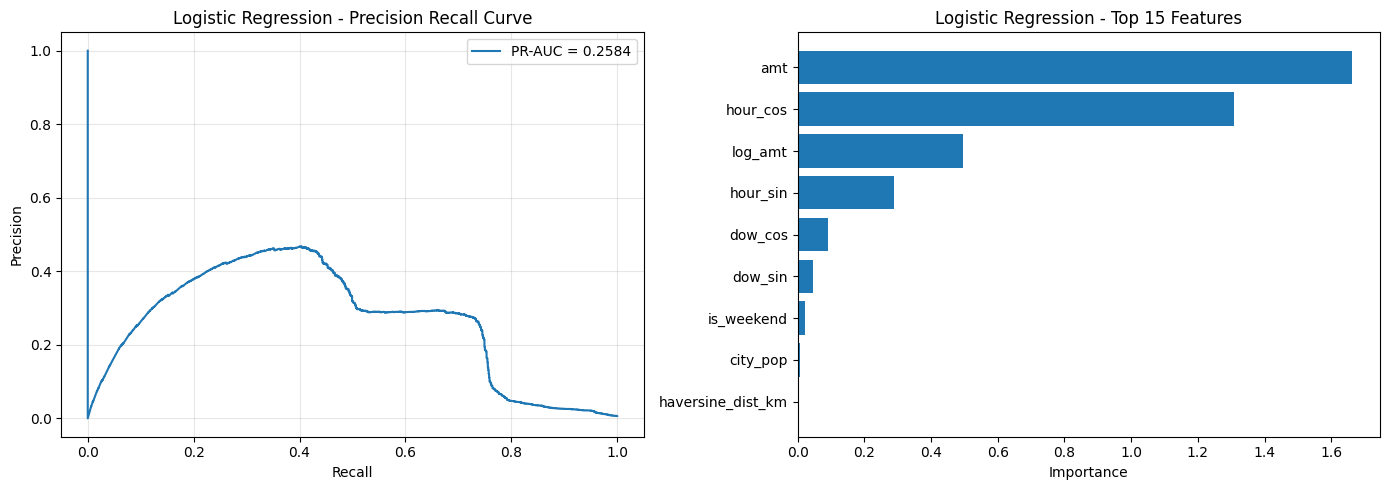


Logistic Regression — Validation Threshold Calibration


""


In [18]:
# Extract Logistic Regression feature importance
lr_importance = pd.DataFrame({
    "feature": static_features,
    "importance": np.abs(pipe.named_steps["clf"].coef_[0])
})

# Sort by importance
lr_importance = lr_importance.sort_values(
    by="importance",
    ascending=False
)

# Display feature importance
lr_importance

# Generate and log diagnostics using validation predictions
lr_thresholds = log_model_diagnostics(
    run_id=lr_run_id,
    y_true=y_val,
    y_probs=val_probs_lr,
    model_name="Logistic Regression",
    feature_importances=lr_importance
)

print("\nLogistic Regression — Validation Threshold Calibration")
lr_thresholds

# 6.2 LightGBM — Static Features: Feature Importance & Diagnostics

🏃 View run lightgbm_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/1efbc40b93174295a65f81832223cc24
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


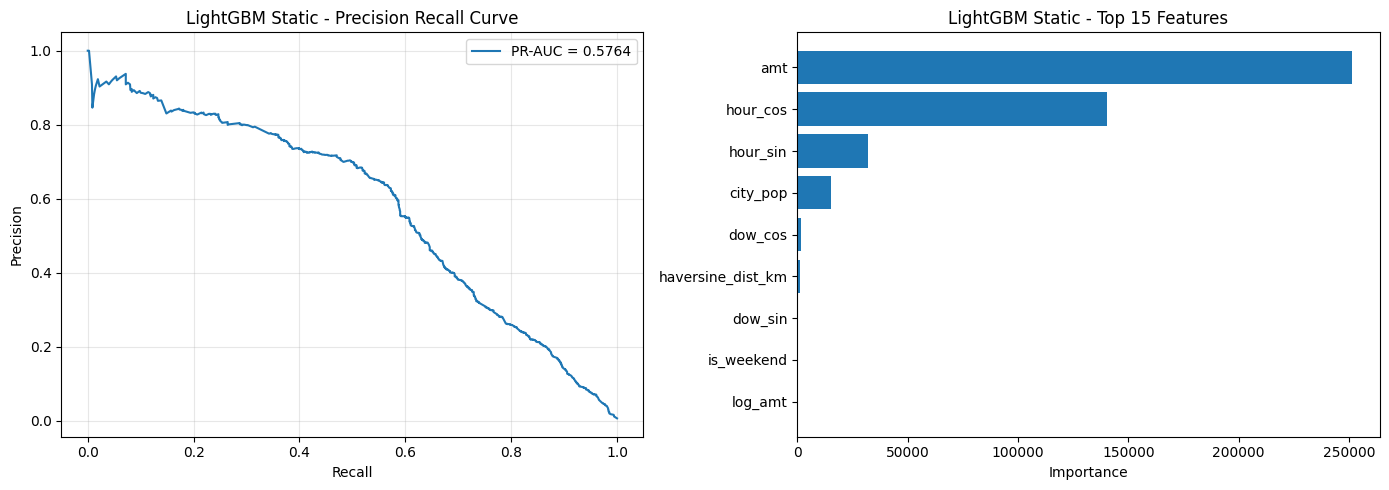


LightGBM Static — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.70,0.398306,0.700337,0.498403
1,0.80,0.688881,0.800434,0.294728
2,0.85,0.840559,0.862069,0.139776
3,0.90,0.905335,0.909091,0.079872


In [19]:
# Extract LightGBM feature importance using gain
lgb_importance = pd.DataFrame({
    "feature": static_features,
    "importance": model_lgb.booster_.feature_importance(
        importance_type="gain"
    )
})

# Sort feature importance
lgb_importance = lgb_importance.sort_values(by="importance",ascending=False)

# Display feature importance
lgb_importance

# Generate and log diagnostics
lgb_thresholds = log_model_diagnostics(run_id=lgb_static_run_id,y_true=y_val,y_probs=val_probs_lgb,
    model_name="LightGBM Static",feature_importances=lgb_importance)

print("\nLightGBM Static — Validation Threshold Calibration")
lgb_thresholds

# 3 LightGBM — Static + Velocity Features: Feature Importance & Diagnostics

🏃 View run lightgbm_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/f677baeb6205407ebad973d17a238481
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


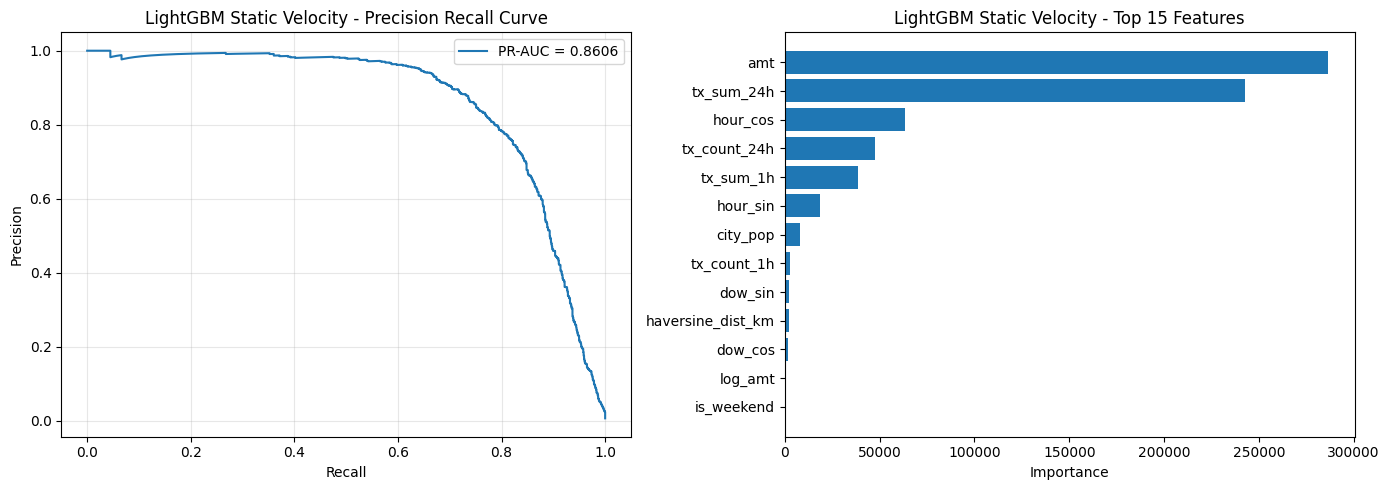


LightGBM Static + Velocity — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.70,0.123514,0.700132,0.846645
1,0.80,0.275325,0.800162,0.786741
2,0.85,0.340170,0.850679,0.750799
3,0.90,0.516166,0.900000,0.704473


In [20]:
# Extract LightGBM feature importance using gain
lgb_velocity_importance = pd.DataFrame({
    "feature": velocity_features,
    "importance": model_lgb_v.booster_.feature_importance(
        importance_type="gain"
    )
})

# Sort feature importance
lgb_velocity_importance = lgb_velocity_importance.sort_values(by="importance",ascending=False)

# Display feature importance
lgb_velocity_importance

# Generate and log diagnostics
lgb_velocity_thresholds = log_model_diagnostics(
    run_id=lgb_velocity_run_id,
    y_true=y_val,
    y_probs=val_probs_lgb_v,
    model_name="LightGBM Static Velocity",
    feature_importances=lgb_velocity_importance
)

print("\nLightGBM Static + Velocity — Validation Threshold Calibration")
lgb_velocity_thresholds

# 4 Random Forest — Static Features: Feature Importance & Diagnostics

🏃 View run random_forest_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ad57bdc68550488b97516488d77b0ff1
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


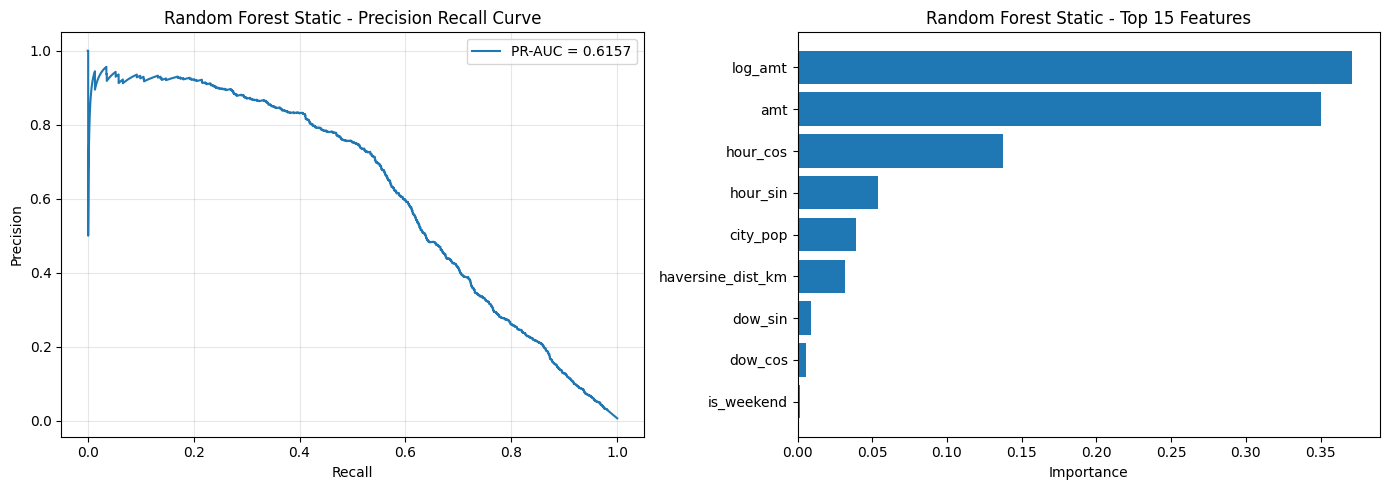


Random Forest Static — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.70,0.792919,0.700617,0.543930
1,0.80,0.938508,0.800000,0.424920
2,0.85,0.969542,0.850485,0.349840
3,0.90,0.990372,0.900585,0.246006


In [21]:
# Extract Random Forest feature importance
rf_importance = pd.DataFrame({
    "feature": static_features,
    "importance": model_rf.feature_importances_
})

# Sort feature importance
rf_importance = rf_importance.sort_values(by="importance",ascending=False)
# Display feature importance
rf_importance

# Generate and log diagnostics
rf_thresholds = log_model_diagnostics(
    run_id=rf_static_run_id,
    y_true=y_val,
    y_probs=val_probs_rf,
    model_name="Random Forest Static",
    feature_importances=rf_importance
)

print("\nRandom Forest Static — Validation Threshold Calibration")
rf_thresholds

# 5 Random Forest — Static + Velocity Features: Feature Importance & Diagnostics

🏃 View run random_forest_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/5bf5c5abeaca44f4b0c26325c06f37ed
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


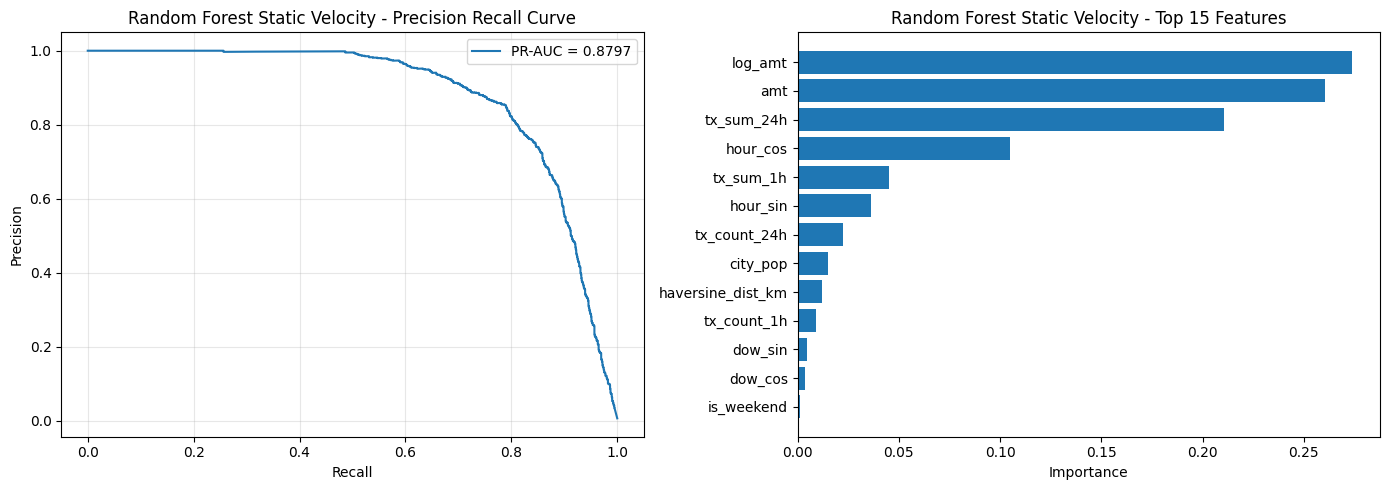


Random Forest Static + Velocity — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.70,0.440424,0.700195,0.861821
1,0.80,0.614225,0.800000,0.811502
2,0.85,0.696013,0.850387,0.789936
3,0.90,0.808568,0.900302,0.714058


In [22]:
# Extract Random Forest feature importance
rf_velocity_importance = pd.DataFrame({
    "feature": velocity_features,
    "importance": model_rf_v.feature_importances_
})

# Sort feature importance
rf_velocity_importance = rf_velocity_importance.sort_values( by="importance",ascending=False)

# Display feature importance
rf_velocity_importance

# Generate and log diagnostics
rf_velocity_thresholds = log_model_diagnostics(
    run_id=rf_velocity_run_id,
    y_true=y_val,
    y_probs=val_probs_rf_v,
    model_name="Random Forest Static Velocity",
    feature_importances=rf_velocity_importance
)

print("\nRandom Forest Static + Velocity — Validation Threshold Calibration")
rf_velocity_thresholds

# 6. XGBoost — Static Features: Feature Importance & Diagnostics

🏃 View run xgboost_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ec9a0bb450d14accaa7a5004f9866f0b
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


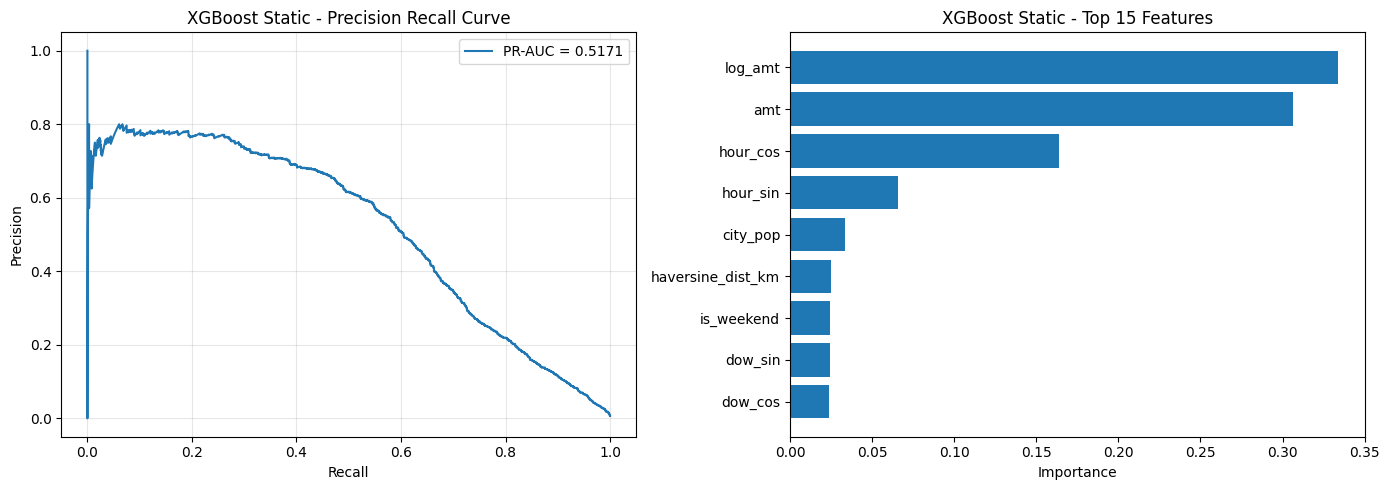


XGBoost Static — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.7,0.989956,0.700434,0.386581
1,0.8,0.997847,0.800000,0.067093


In [23]:
# Extract XGBoost feature importance
xgb_importance = pd.DataFrame({
    "feature": static_features,
    "importance": model_xgb.feature_importances_
})

# Sort feature importance
xgb_importance = xgb_importance.sort_values(by="importance",ascending=False)

# Display feature importance
xgb_importance

# Generate and log diagnostics
xgb_thresholds = log_model_diagnostics(
    run_id=xgb_static_run_id,
    y_true=y_val,
    y_probs=val_probs_xgb,
    model_name="XGBoost Static",
    feature_importances=xgb_importance
)

print("\nXGBoost Static — Validation Threshold Calibration")
xgb_thresholds

# 7. XGBoost — Static + Velocity Features: Feature Importance & Diagnostics

🏃 View run xgboost_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ecb78a48e0504da98806c4d2b3bee5b4
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


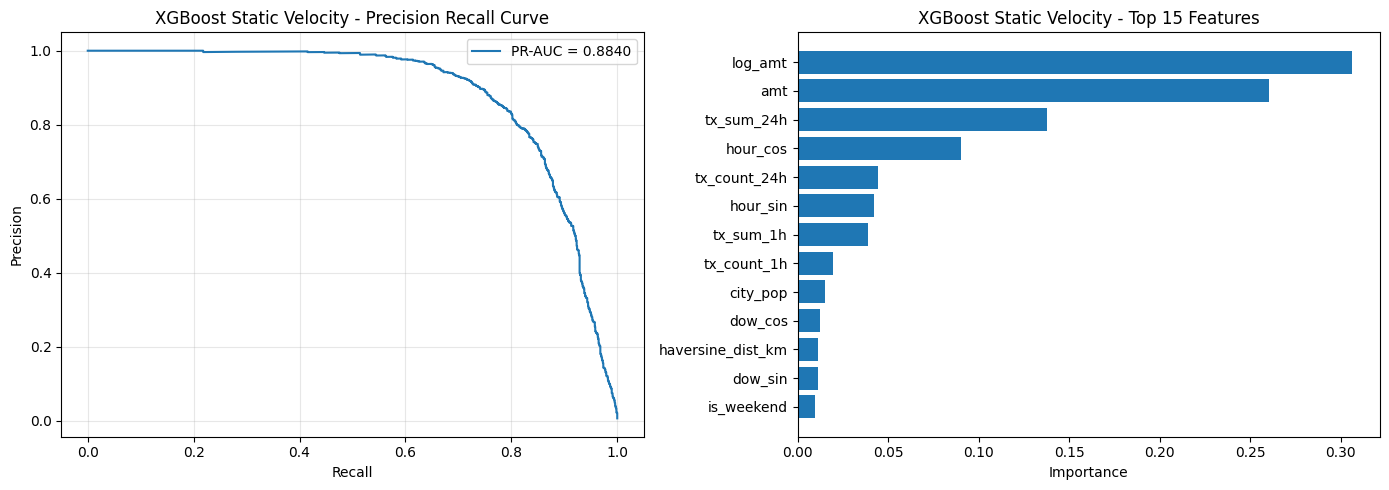


XGBoost Static + Velocity — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.70,0.912493,0.700130,0.863419
1,0.80,0.957682,0.800000,0.811502
2,0.85,0.971419,0.850216,0.784345
3,0.90,0.982655,0.900000,0.740415


In [24]:
# Extract XGBoost feature importance
xgb_velocity_importance = pd.DataFrame({
    "feature": velocity_features,
    "importance": model_xgb_v.feature_importances_
})

# Sort feature importance
xgb_velocity_importance = xgb_velocity_importance.sort_values(by="importance",ascending=False)

# Display feature importance
xgb_velocity_importance

# Generate and log diagnostics
xgb_velocity_thresholds = log_model_diagnostics(
    run_id=xgb_velocity_run_id,
    y_true=y_val,
    y_probs=val_probs_xgb_v,
    model_name="XGBoost Static Velocity",
    feature_importances=xgb_velocity_importance
)

print("\nXGBoost Static + Velocity — Validation Threshold Calibration")
xgb_velocity_thresholds

# 8. CatBoost — Static Features: Feature Importance & Diagnostics

🏃 View run catboost_static at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/ac3d2a1807d04d5b905ef40010c0f342
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


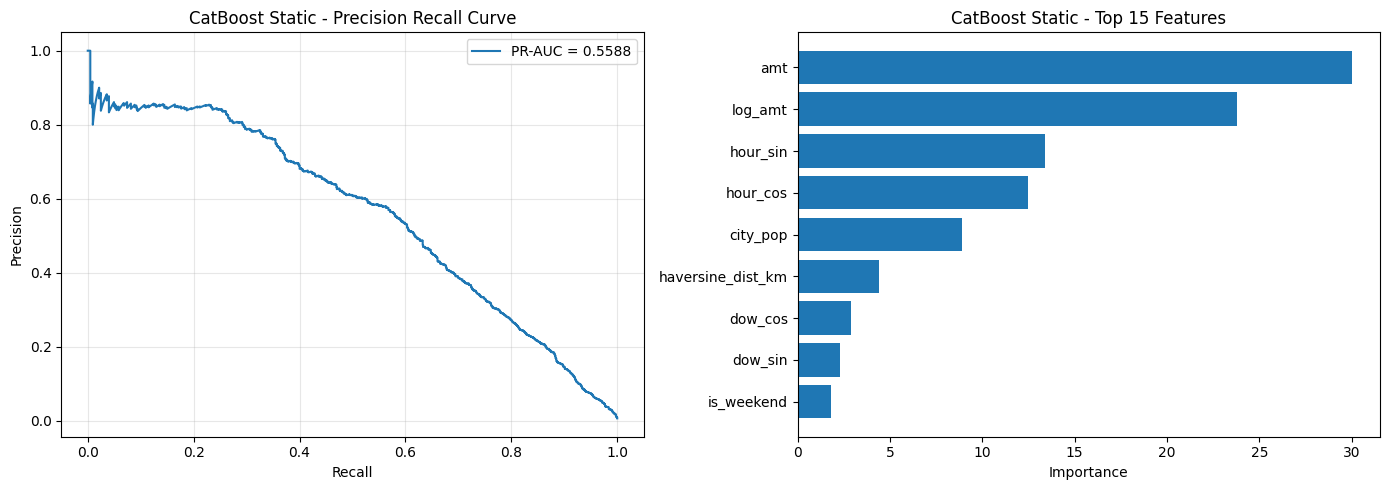


CatBoost Static — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.70,0.988485,0.700288,0.388179
1,0.80,0.994243,0.800000,0.293930
2,0.85,0.995313,0.850877,0.232428
3,0.90,0.997098,0.900000,0.021565


In [25]:
# Extract CatBoost feature importance
cat_importance = pd.DataFrame({
    "feature": static_features,
    "importance": model_cat.get_feature_importance()
})

# Sort feature importance
cat_importance = cat_importance.sort_values(by="importance",ascending=False)

# Display feature importance
cat_importance

# Generate and log diagnostics
cat_thresholds = log_model_diagnostics(
    run_id=cat_static_run_id,
    y_true=y_val,
    y_probs=val_probs_cat,
    model_name="CatBoost Static",
    feature_importances=cat_importance
)

print("\nCatBoost Static — Validation Threshold Calibration")
cat_thresholds

# 9. CatBoost — Static + Velocity Features: Feature Importance & Diagnostics

🏃 View run catboost_static_velocity at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/e94f5394736d49c5bf06e49bbd4466ba
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1


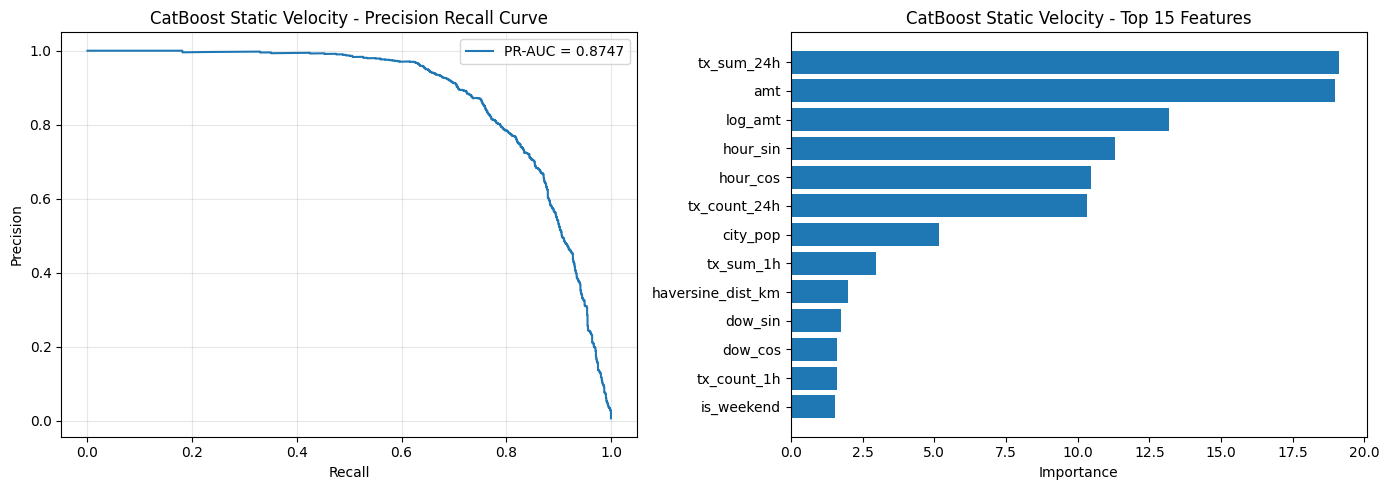


CatBoost Static + Velocity — Validation Threshold Calibration


,target_precision,threshold,achieved_precision,achieved_recall
0,0.70,0.937406,0.700065,0.853834
1,0.80,0.964110,0.800487,0.788339
2,0.85,0.973176,0.850492,0.758786
3,0.90,0.982876,0.900407,0.707668


In [26]:
# Extract CatBoost feature importance
cat_velocity_importance = pd.DataFrame({
    "feature": velocity_features,
    "importance": model_cat_v.get_feature_importance()
})

# Sort feature importance
cat_velocity_importance = cat_velocity_importance.sort_values(by="importance",ascending=False)

# Display feature importance
cat_velocity_importance

# Generate and log diagnostics
cat_velocity_thresholds = log_model_diagnostics(
    run_id=cat_velocity_run_id,
    y_true=y_val,
    y_probs=val_probs_cat_v,
    model_name="CatBoost Static Velocity",
    feature_importances=cat_velocity_importance
)

print("\nCatBoost Static + Velocity — Validation Threshold Calibration")
cat_velocity_thresholds

# Consolidated Threshold Calibration Summary

In [27]:
# Collect threshold calibration results from all nine experiments
threshold_results = {
    "Logistic Regression - Static": lr_thresholds,
    "LightGBM - Static": lgb_thresholds,
    "LightGBM - Static + Velocity": lgb_velocity_thresholds,
    "Random Forest - Static": rf_thresholds,
    "Random Forest - Static + Velocity": rf_velocity_thresholds,
    "XGBoost - Static": xgb_thresholds,
    "XGBoost - Static + Velocity": xgb_velocity_thresholds,
    "CatBoost - Static": cat_thresholds,
    "CatBoost - Static + Velocity": cat_velocity_thresholds
}

# Combine non-empty threshold results
threshold_tables = []

for model_name, result_df in threshold_results.items():
    if not result_df.empty:
        temp_df = result_df.copy()
        temp_df["model"] = model_name
        threshold_tables.append(temp_df)

if threshold_tables:
    threshold_comparison_df = pd.concat(
        threshold_tables,
        ignore_index=True
    )

    # Arrange columns
    threshold_comparison_df = threshold_comparison_df[
        [
            "model",
            "target_precision",
            "threshold",
            "achieved_precision",
            "achieved_recall"
        ]
    ]

    # Sort by target precision and recall
    threshold_comparison_df = threshold_comparison_df.sort_values(
        by=["target_precision", "achieved_recall"],
        ascending=[True, False]
    ).reset_index(drop=True)

    threshold_comparison_df

    # Save consolidated results
    threshold_path = REPORTS_DIR / "threshold_calibration_comparison.csv"

    threshold_comparison_df.to_csv(threshold_path,index=False)

    # Log consolidated results to MLflow
    with mlflow.start_run(run_name="threshold_calibration_comparison"):
        mlflow.log_artifact(
            str(threshold_path),
            artifact_path="threshold_comparison"
        )

        mlflow.log_param(
            "threshold_targets",
            "70%, 80%, 85%, 90%"
        )

        mlflow.log_param(
            "number_of_experiments",
            len(threshold_results)
        )

    print(f"\nThreshold comparison saved to: {threshold_path}")
    print("Threshold comparison logged to MLflow.")

else:
    print("No threshold calibration results available.")

🏃 View run threshold_calibration_comparison at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/6c59c0adacf54fbfb6f401cf732cf891
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1

Threshold comparison saved to: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\threshold_calibration_comparison.csv
Threshold comparison logged to MLflow.


# Model Selection — Validation Results


Our  model selection is based on validation results


- Primary candidate: XGBoost — Static + Velocity (highest validation PR-AUC: 0.8840).

- Challenger model: Random Forest — Static + Velocity (validation PR-AUC: 0.8797).

In [28]:
# Select the two leading candidate models
candidate_names = [
    "XGBoost",
    "Random Forest"
]

candidate_df = comparison_df[
    (comparison_df["Model"].isin(candidate_names)) &
    (comparison_df["Feature Set"] == "Static + Velocity")
].copy()

# Extract 90% precision threshold results
threshold_90 = threshold_comparison_df[
    threshold_comparison_df["target_precision"] == 0.90
][["model", "threshold", "achieved_precision", "achieved_recall"]].copy()

# Match threshold results with model comparison
candidate_df = candidate_df.merge(
    threshold_90,
    left_on="Model",
    right_on="model",
    how="left"
)

# Add candidate roles
candidate_df["Candidate Role"] = candidate_df["Model"].map({
    "XGBoost": "Primary Candidate",
    "Random Forest": "Challenger"
})

# Select and arrange columns
selection_summary = candidate_df[
    [
        "Candidate Role",
        "Model",
        "Feature Set",
        "pr_auc",
        "roc_auc",
        "brier_score",
        "threshold",
        "achieved_precision",
        "achieved_recall"
    ]
].sort_values(by="pr_auc",ascending=False).reset_index(drop=True)

# Display results
selection_summary

# Save selection summary
selection_path = REPORTS_DIR / "baseline_model_selection.csv"

selection_summary.to_csv(selection_path,index=False)

# Log to MLflow
with mlflow.start_run(run_name="baseline_model_selection"):
    mlflow.log_artifact(
        str(selection_path),
        artifact_path="model_selection"
    )

    mlflow.log_param(
        "primary_candidate",
        "XGBoost Static + Velocity"
    )

    mlflow.log_param(
        "challenger",
        "Random Forest Static + Velocity"
    )

print(f"\nSelection summary saved to: {selection_path}")
print("Baseline model selection logged to MLflow.")

🏃 View run baseline_model_selection at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1/runs/9080c0f88f664a99a288028895f89584
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/1

Selection summary saved to: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\baseline_model_selection.csv
Baseline model selection logged to MLflow.


## Key Insights

1. **Best Baseline Model:** XGBoost with Static + Velocity features achieved the highest validation PR-AUC of **0.8840**, followed by Random Forest (0.8797), CatBoost (0.8747), and LightGBM (0.8606).

2. **Impact of Velocity Features:** Transaction velocity features significantly improved fraud detection across all four tree-based models, demonstrating the importance of historical transaction behaviour.

3. **Important Predictors:** `amt`, `log_amt`, `tx_sum_24h`, `tx_count_24h`, and `tx_sum_1h` emerged as important predictive features across the experiments.

4. **Precision-Recall Trade-off:** XGBoost + Velocity achieved **74.04% recall at 90% precision**, demonstrating its ability to identify fraudulent transactions while maintaining a high precision requirement on validation data.

5. **Model Interpretability:** Feature importance analysis and Precision-Recall curves helped understand model behaviour and identify influential fraud indicators.

6. **Experiment Tracking:** MLflow and DagsHub provided centralized tracking of model parameters, validation metrics, trained models, diagnostic plots, and threshold calibration artifacts.

